In [1]:
import os
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import numpy as np
from pickle import dump


import json
import matplotlib.pyplot as plt
from typing import Iterable
from tensorflow.keras.optimizers import Adam
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.metrics import mean_absolute_error


from keras.layers import Dense, BatchNormalization, Activation, Add, Input

from keras.models import model_from_json
from keras.regularizers import l2, l1_l2
from keras import Model
from tensorflow import Tensor
from typing import List
from tensorflow.keras.optimizers import Adam

In [2]:
def load_time_based_data(directory):
    """
    function for loading the time based data
    returns(2): list of each data, and names of each data
    """
    dfs = []
    df_time_names=[]
    count = 0
    for subdir, dirs, files in os.walk(directory):
        for file in files:
            filename = directory + '/'+file
            if filename.endswith(".csv") and "time" in filename:
                df = pd.read_csv(filename, sep=',', decimal='.')
                wellname = file.split('.csv')
                df['WellName'] = wellname[0]
                df_time_names.append(wellname[0])
                dfs.append(df)
                count += 1
                
                
    return dfs,df_time_names




In [3]:

def preProcess(datafolder,
                input_var_list, 
                output_var, 
                training_dfs,
                train_percent
 
                ):
    """
    
    :input_var_list: list containing input variables (refers to column name in the data)
    :output_var: output variable. e.g. ROP
    :training_dfs: csv files chosen for training
    :train_percent: proportion used for splitting data e.g. 0.1 means first 10% for training and 90% for testing

    scaler_option default is  'min_maxScaler'
    
    """
    
    time_data, df_time_names = load_time_based_data(datafolder)
    
    

 
    #concatenate all TIME datasets
    all_data_concat = pd.DataFrame()
    for dataset in df_time_names:
        idx = df_time_names.index(dataset)
        all_data_concat = pd.concat([all_data_concat,time_data[idx]])

    #make an array of all datasets with columns of input vriables   
    inputs = np.zeros([len(all_data_concat),len(input_var_list)])
    for i in range(len(input_var_list)):
        inputs[:,i] = all_data_concat[input_var_list[i]]

    #fit a scaler to all time datasets
    scaler = MinMaxScaler()
    scaler.fit(inputs)
    ##
    dump(scaler, open('scaler.pkl', 'wb'))


    #concatenate all training datasets and Validation 
    training_data_concat = pd.DataFrame()
    validation_data_concat = pd.DataFrame()
   

    
    for dataset in training_dfs: 
            #get the chosen file from the dataset
            idx = df_time_names.index(dataset)
            #to ensure correct files are chosen. when importing files, the sequence are not in the same order.
            current_well_data = time_data[idx]
            num_observations = current_well_data.shape[0]
            
     
            train_index=int(num_observations*train_percent)

            training_data_concat = pd.concat([training_data_concat,current_well_data[:train_index]])
            validation_data_concat = pd.concat([validation_data_concat,current_well_data[train_index:]])
                
                


    #prepare input frame
    train_input = np.zeros([len(training_data_concat),len(input_var_list)])
    validation_input = np.zeros([len(validation_data_concat),len(input_var_list)])

    for i in range(len(input_var_list)):
        train_input[:,i] = training_data_concat[input_var_list[i]]
        validation_input[:,i] = validation_data_concat[input_var_list[i]]

    #scale input
    scaled_train_input= scaler.transform(train_input)
    scaled_validation_input= scaler.transform(validation_input)
    
    #prepare output
    train_output = np.expand_dims(training_data_concat[output_var], 1)
    validation_output = np.expand_dims(validation_data_concat[output_var], 1)
        

    return [scaled_train_input,train_output,scaled_validation_input,validation_output]
    

In [4]:

def bn_layer(
    x: Tensor, 
    hidden_units: int,
    l1_lambda: float = 0.0001, 
    l2_lambda: float = 0.0005, 
    act_func: str = 'relu'
) -> Tensor:
    """
    Convenience function for adding batch normed layers to a Keras model defined using 
    the functional API (will not work if using Sequential models API).
    Call during model definition to add to Tensorflow computational graph.
    :param x: Tensor output of previous layer, assumes it is same size as hidden_units
    :param hidden_units: Number of hidden units in layer.
    :param l1_lambda: Float value for L1 regularization lamda parameter (feature selection)
    :param l2_lambda: Float value for L2 regularization lamda parameter (weight decay)
    :param act_func: Valid string alias for Tensorflow activation functions.
    :return: Tensor, output of the residual block.  
    """
    y = Dense(hidden_units, 
              kernel_regularizer=l1_l2(l1=l1_lambda, l2=l2_lambda), 
              use_bias=False)(x)
    y = BatchNormalization()(y)
    y = Activation(act_func)(y)

    return y


def get_nn_model(
    n_input_vars: int,
    n_outputs: int = 1,
    fc_layer_sizes: List[int] = [32, 32],
    l1_lambda: float = 0.001,
    l2_lambda: float = 0.005,
    act_func: str = 'relu',
    loss_func: str = 'mean_absolute_error',
    out_activation: str = 'linear',
    l_r: float = 0.02,
    return_json: bool = False
):
    """
    Convenience function for defining a simple configurable feed-forward neural network model, 
    for either regression or classification.
    Default settings are for regression model, for classification use sigmoid or softmax 
    output activation, and cross-entropy for loss.

    :param n_input_vars: Int number of input variables.
    :param n_outputs: Int number of output units.
    :param fc_layer_sizes: Int number of hidden units in hidden layers.
    :param l1_lambda: Float value for L1 regularization lamda parameter (feature selection)
    :param l2_lambda: Float value for L2 regularization lamda parameter (weight decay)
    :param act_func: String alias for activation functions to use in hidden layers.
    :param loss_func: String alias for loss function to use for training.
    :param out_activation: String alias for output layer activation function
    :param l_r: Learning rate to pass to Model.compile()
    :param return_json: Specifies whether to return the model object or a JSON string 
                        representation of model.
    :return: Keras Model or JSON representation.
    """

    inputs = Input(shape=(n_input_vars,)) #Input() is used to instantiate a Keras tensor.  indicates that the expected input will be batches of 32-dimensional vectors.

    # NOTE - for tensor addition to work, input tensor size should be compatible 
    # with hidden units value passed to res block

    x = inputs

    # Add hidden layers to model
    for layer_size in fc_layer_sizes:
        x = bn_layer(x=x, hidden_units=layer_size, l1_lambda=l1_lambda, 
                     l2_lambda=l2_lambda, act_func=act_func)

    # Final layer
    output = Dense(n_outputs, activation=out_activation)(x)

    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=Adam(learning_rate=l_r), loss=loss_func)

    if return_json:
        m_json = model.to_json()
        return m_json
    else:
        return model

In [5]:
def plot_train_history(
    train_loss: Iterable, 
    val_loss: Iterable, 
    loss_func: str, 
    fig_path: str,
):

    """
    function for plotting the training loss at each epoch
    """

    plt.figure()
    plt.plot(train_loss, label='Training set')
    plt.plot(val_loss, label='Validation set')
    plt.title("Training history")
    plt.xlabel('Epochs')
    plt.ylabel(f"Loss ({loss_func})")
    plt.legend()
    plt.savefig(fig_path, dpi=170, bbox_inches='tight')
    plt.show()
    plt.clf()
    plt.close()

    return

### load configuration json file

In [6]:
# Opening JSON file
f = open('/Users/fjpax/Desktop/Volve clean/config_baseM.json', 'r')
 
# returns JSON object as a dictionary
config = json.load(f)


### preprocess data

In [7]:
trainX, trainY, valX,valY= preProcess(config['datafolder'],
                                input_var_list=config['input_var_list'], 
                                output_var=config['output_var_list'], 
                                training_dfs=config['training_dfs'],
                                train_percent=config['train_percent'])

### Define a model

In [8]:
my_model = get_nn_model(
            n_input_vars=config['n_inputs'],
            n_outputs=config['n_outputs'],
            fc_layer_sizes=config['layer_sizes'], # e.g [30, 20, 10, 20, 30] 
            l1_lambda=config['l1_lambda'],
            l2_lambda=config['l2_lambda'],
            act_func=config['act_func'],
            loss_func=config['loss_func'],
            out_activation=config['output_activation'],
            return_json=False  # set to true if you want the architecture of the model only, as JSON-formatted string
            )   

2021-12-07 17:39:11.609480: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


### Train Model

In [9]:
# add callbacks for training process, e.g. Early Stopping
callbacks_list = [
                    keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=100),

                    ###second callback for saving best model based on validation loss
                    keras.callbacks.ModelCheckpoint(
                    filepath="checkpoint_path_model.h5",
                    monitor="val_loss", 
                    save_best_only=True)] 

# Train a model
history = my_model.fit(
                        trainX, 
                        trainY,
                        epochs=config['n_epochs'], 
                        batch_size=config['batch_size'], 
                        verbose=0, 
                        validation_data=(valX,valY), 
                        callbacks=callbacks_list)

2021-12-07 17:39:11.752158: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:185] None of the MLIR Optimization Passes are enabled (registered 2)


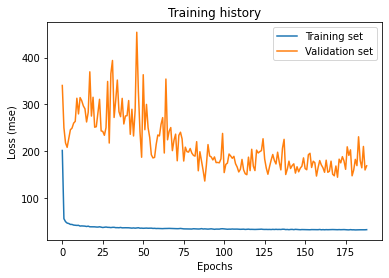

In [10]:
# plot of the training history
plot_train_history(
                    train_loss=history.history['loss'], 
                    val_loss=history.history['val_loss'], 
                    loss_func=config['loss_func'], 
                    fig_path=config['fig_path']
                    )

### predict using final model based on loss

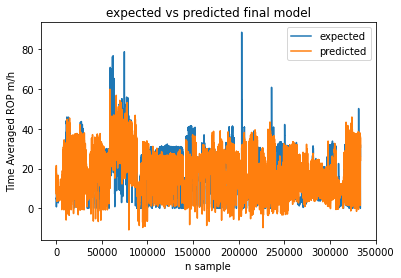

MAE:6.489648752323646


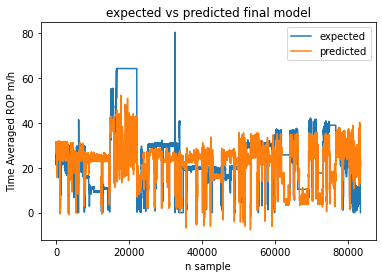

MAE:9.520155258641294


In [11]:
#save final model based on loss
my_model.save('final model.h5')

#Using final model based on loss, predict on train 
plt.plot(trainY, label='expected')
plt.plot(my_model.predict(trainX), label='predicted')
plt.title("expected vs predicted final model")
plt.xlabel('n sample')
plt.ylabel(config['output_var_list'])
plt.legend()
plt.show()
#print MAE
print('MAE:'+ str(mean_absolute_error(trainY, my_model.predict(trainX))))

#Using final model based on loss, predict on val data
plt.figure()
plt.plot( valY, label='expected')
plt.plot(my_model.predict(valX), label='predicted')
plt.title("expected vs predicted final model")
plt.xlabel('n sample')
plt.ylabel(config['output_var_list'])
plt.legend()
plt.show()
#print MAE
print('MAE:'+ str(mean_absolute_error(valY, my_model.predict(valX))))

### predict using checkpoint model

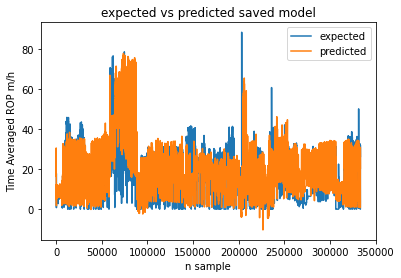

MAE:7.392992363973344


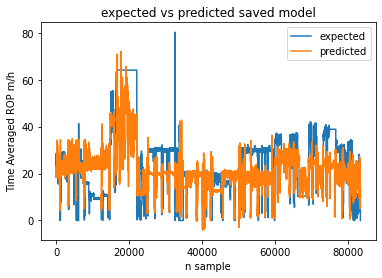

MAE:9.288201070891587


In [12]:
#Using final model based on VAL loss, predict on train data
my_model1=keras.models.load_model("checkpoint_path_model.h5")
plt.figure()
plt.plot(trainY, label='expected')
plt.plot(my_model1.predict(trainX), label='predicted')
plt.title("expected vs predicted saved model")
plt.xlabel('n sample')
plt.ylabel(config['output_var_list'])
plt.legend()
plt.show()
print('MAE:'+ str(mean_absolute_error(trainY, my_model1.predict(trainX))))

#Using final model based on VAL loss, predict on VAL data 
plt.figure()
plt.plot(valY, label='expected')
plt.plot(my_model1.predict(valX), label='predicted')
plt.title("expected vs predicted saved model")
plt.xlabel('n sample')
plt.ylabel(config['output_var_list'])
plt.legend()
plt.show()
print('MAE:'+ str(mean_absolute_error(valY, my_model1.predict(valX))))


